In [2]:
import sqlite3
import pandas as pd

conexao = sqlite3.connect("dados/academia.db")

pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table'",
    conexao
)

,name
0,unidades
1,planos
2,alunos
3,matriculas
4,pagamentos
5,checkins


In [2]:
alunos = pd.read_sql_query("SELECT * FROM alunos", conexao)

NameError: name 'pd' is not defined

In [3]:
import sqlite3
import pandas as pd

conexao = sqlite3.connect("dados/academia.db")

unidades    = pd.read_sql_query("SELECT * FROM unidades", conexao)
planos      = pd.read_sql_query("SELECT * FROM planos", conexao)
alunos      = pd.read_sql_query("SELECT * FROM alunos", conexao)
matriculas  = pd.read_sql_query("SELECT * FROM matriculas", conexao)
pagamentos  = pd.read_sql_query("SELECT * FROM pagamentos", conexao)
checkins    = pd.read_sql_query("SELECT * FROM checkins", conexao)

In [4]:
matriculas.head(10)

,id_matricula,id_aluno,id_unidade,id_plano,data_inicio,data_fim,status,motivo_cancelamento,valor_mensal
0,1,1,3,2,2026-02-25,2026-05-30,cancelada,preço,119.0
1,2,2,2,3,2025-02-02,NaN,ativa,NaN,169.0
2,3,3,1,1,2025-12-10,2026-06-20,cancelada,NaN,89.0
3,4,4,1,3,2025-10-25,NaN,ativa,NaN,169.0
4,5,5,3,3,2026-01-27,2026-09-30,cancelada,mudança de cidade,169.0
5,6,6,2,1,2026-04-11,2026-06-04,cancelada,NaN,89.0
6,7,7,3,3,2024-05-23,NaN,ativa,NaN,169.0
7,8,8,1,2,2025-11-08,2026-09-30,cancelada,falta de tempo,119.0
8,9,9,3,1,2025-06-11,2026-08-15,cancelada,NaN,119.0
9,10,10,4,2,2026-07-15,NaN,ativa,NaN,119.0


In [5]:
pd.crosstab(matriculas["status"], matriculas["data_fim"].isna())

data_fim,False,True
status,,
Cancelada,50,0
ativa,0,1542
cancelada,1021,6
trancada,0,38


In [6]:
matriculas["status_limpo"] = matriculas["status"].str.lower()

matriculas["status_limpo"].value_counts()

status_limpo
ativa        1542
cancelada    1077
trancada       38
Name: count, dtype: int64

In [7]:
query = """
SELECT id_plano,
       COUNT(*) AS total,
       SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) AS canceladas,
       ROUND(100.0 * SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_canceladas
FROM matriculas
WHERE LOWER(status) <> 'trancada'
GROUP BY id_plano
ORDER BY id_plano
"""

pd.read_sql_query(query, conexao)

,id_plano,total,canceladas,pct_canceladas
0,1,1326,636,48.0
1,2,805,309,38.4
2,3,488,132,27.0


In [8]:
canceladas = matriculas[matriculas["status_limpo"] == "cancelada"].copy()

canceladas["dias"] = (
    pd.to_datetime(canceladas["data_fim"]) - pd.to_datetime(canceladas["data_inicio"])
).dt.days

canceladas["dias"].describe()

count    1071.000000
mean      292.278245
std       213.795087
min       -10.000000
25%       112.000000
50%       251.000000
75%       414.000000
max       988.000000
Name: dias, dtype: float64

In [9]:
canceladas[canceladas["dias"] < 0]

,id_matricula,id_aluno,id_unidade,id_plano,data_inicio,data_fim,status,motivo_cancelamento,valor_mensal,status_limpo,dias
1010,1011,994,1,1,2024-08-24,2024-08-14,cancelada,preço,89.0,cancelada,-10.0
1177,1178,1152,4,1,2024-08-09,2024-07-30,cancelada,estrutura da unidade,89.0,cancelada,-10.0
1571,1572,1537,1,1,2024-04-11,2024-04-01,Cancelada,NaN,89.0,cancelada,-10.0
2336,2337,2285,3,1,2024-04-06,2024-03-27,cancelada,estrutura da unidade,119.0,cancelada,-10.0


In [10]:
negativas = canceladas[canceladas["dias"] < 0]

negativas[["id_matricula", "data_inicio", "data_fim"]]

,id_matricula,data_inicio,data_fim
1010,1011,2024-08-24,2024-08-14
1177,1178,2024-08-09,2024-07-30
1571,1572,2024-04-11,2024-04-01
2336,2337,2024-04-06,2024-03-27


In [11]:
ids = negativas["id_matricula"].tolist()

pagamentos[pagamentos["id_matricula"].isin(ids)].sort_values(["id_matricula", "data_vencimento"])

,id_pagamento,id_matricula,data_vencimento,data_pagamento,valor,status
28582,28583,1011,2024-08-29,2024-09-11,89.0,pago
6641,6642,1011,2024-09-29,2024-09-26,89.0,pago
1124,1125,1011,2024-10-29,2024-10-26,89.0,pago
3948,3949,1011,2024-11-29,2024-12-02,89.0,pago
21478,21479,1011,2024-12-29,2024-12-31,89.0,pago
17313,17314,1178,2024-08-14,2024-08-16,89.0,pago
16791,16792,1178,2024-09-14,2024-09-17,89.0,pago
1878,1879,1572,2024-04-16,2024-04-19,89.0,pago
8164,8165,1572,2024-05-16,2024-05-18,89.0,pago
19633,19634,1572,2024-06-16,2024-06-16,89.0,pago


In [13]:
pagamentos[pagamentos["id_matricula"].isin(ids)]["id_matricula"].nunique()

4

In [14]:
datas = (
    pagamentos[pagamentos["id_matricula"].isin(ids)]
    .groupby("id_matricula")["data_vencimento"]
    .agg(primeiro="min", ultimo="max")
)

datas

,primeiro,ultimo
id_matricula,,
1011,2024-08-29,2024-12-29
1178,2024-08-14,2024-09-14
1572,2024-04-16,2025-10-16
2337,2024-04-11,2026-04-11


In [15]:
mascara = matriculas["id_matricula"].isin(datas.index)

matriculas["data_inicio_corrigida"] = matriculas["data_inicio"]
matriculas["data_fim_corrigida"] = matriculas["data_fim"]

matriculas.loc[mascara, "data_inicio_corrigida"] = matriculas.loc[mascara, "id_matricula"].map(datas["primeiro"])
matriculas.loc[mascara, "data_fim_corrigida"] = matriculas.loc[mascara, "id_matricula"].map(datas["ultimo"])

matriculas["corrigida"] = mascara

matriculas[mascara][["id_matricula", "data_inicio", "data_fim", "data_inicio_corrigida", "data_fim_corrigida", "corrigida"]]

,id_matricula,data_inicio,data_fim,data_inicio_corrigida,data_fim_corrigida,corrigida
1010,1011,2024-08-24,2024-08-14,2024-08-29,2024-12-29,True
1177,1178,2024-08-09,2024-07-30,2024-08-14,2024-09-14,True
1571,1572,2024-04-11,2024-04-01,2024-04-16,2025-10-16,True
2336,2337,2024-04-06,2024-03-27,2024-04-11,2026-04-11,True


In [16]:
canceladas = matriculas[matriculas["status_limpo"] == "cancelada"].copy()

canceladas["dias"] = (
    pd.to_datetime(canceladas["data_fim_corrigida"]) - pd.to_datetime(canceladas["data_inicio_corrigida"])
).dt.days

(canceladas["dias"] <= 31).sum()

np.int64(1)

In [17]:
query = """
SELECT id_unidade,
       COUNT(*) AS total,
       SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) AS canceladas,
       ROUND(100.0 * SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_canceladas
FROM matriculas
WHERE LOWER(status) <> 'trancada'
GROUP BY id_unidade
ORDER BY id_unidade
"""

pd.read_sql_query(query, conexao)

,id_unidade,total,canceladas,pct_canceladas
0,1,729,285,39.1
1,2,529,209,39.5
2,3,471,244,51.8
3,4,540,207,38.3
4,5,350,132,37.7


In [18]:
query = """
SELECT motivo_cancelamento,
       COUNT(*) AS qtd
FROM matriculas
WHERE id_unidade = 3
  AND LOWER(status) = 'cancelada'
GROUP BY motivo_cancelamento
ORDER BY qtd DESC
"""

pd.read_sql_query(query, conexao)

,motivo_cancelamento,qtd
0,NaN,95
1,preço,37
2,outro,28
3,mudança de cidade,28
4,falta de tempo,26
5,estrutura da unidade,24
6,saúde,6


In [19]:
query = """
SELECT motivo_cancelamento,
       COUNT(*) AS qtd
FROM matriculas
WHERE LOWER(status) = 'cancelada'
GROUP BY motivo_cancelamento
ORDER BY qtd DESC
"""

pd.read_sql_query(query, conexao)

,motivo_cancelamento,qtd
0,NaN,405
1,falta de tempo,183
2,mudança de cidade,115
3,preço,106
4,outro,95
5,estrutura da unidade,94
6,saúde,79


In [22]:
query = """
SELECT motivo_cancelamento,
       ROUND(100.0 * SUM(CASE WHEN id_unidade = 3 THEN 1 ELSE 0 END)
             / SUM(SUM(CASE WHEN id_unidade = 3 THEN 1 ELSE 0 END)) OVER (), 1) AS pct_zona_leste,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_geral
FROM matriculas
WHERE LOWER(status) = 'cancelada'
GROUP BY motivo_cancelamento
ORDER BY pct_zona_leste DESC
"""

pd.read_sql_query(query, conexao)

,motivo_cancelamento,pct_zona_leste,pct_geral
0,NaN,38.9,37.6
1,preço,15.2,9.8
2,mudança de cidade,11.5,10.7
3,outro,11.5,8.8
4,falta de tempo,10.7,17.0
5,estrutura da unidade,9.8,8.7
6,saúde,2.5,7.3


In [23]:
query = """
SELECT id_plano,
       id_unidade,
       ROUND(AVG(valor_mensal), 1) AS valor_medio,
       MIN(valor_mensal) AS minimo,
       MAX(valor_mensal) AS maximo
FROM matriculas
GROUP BY id_plano, id_unidade
ORDER BY id_plano, id_unidade
"""

pd.read_sql_query(query, conexao)

,id_plano,id_unidade,valor_medio,minimo,maximo
0,1,1,89.0,89.0,89.0
1,1,2,89.0,89.0,89.0
2,1,3,110.6,89.0,119.0
3,1,4,89.0,89.0,89.0
4,1,5,89.0,89.0,89.0
5,2,1,119.0,119.0,119.0
6,2,2,119.0,119.0,119.0
7,2,3,119.0,119.0,119.0
8,2,4,119.0,119.0,119.0
9,2,5,119.0,119.0,119.0


In [24]:
query = """
SELECT m.id_matricula,
       m.id_aluno,
       a.nome,
       m.data_inicio,
       m.data_fim,
       m.status,
       m.valor_mensal
FROM matriculas m
JOIN alunos a ON a.id_aluno = m.id_aluno
WHERE m.id_unidade = 3
  AND m.id_plano = 1
ORDER BY m.valor_mensal, m.data_inicio
"""

zl_basico = pd.read_sql_query(query, conexao)
zl_basico

,id_matricula,id_aluno,nome,data_inicio,data_fim,status,valor_mensal
0,1365,1334,Vanessa Costa Mendes,2024-01-05,2026-02-21,cancelada,89.0
1,2066,2022,Leonardo Carvalho Santos,2024-01-08,2025-05-04,cancelada,89.0
2,682,672,Renato Oliveira Santos,2024-01-23,2024-10-31,cancelada,89.0
3,519,512,Wesley Ribeiro Costa,2024-01-28,2025-09-07,cancelada,89.0
4,944,929,Helena Araújo Almeida,2024-02-03,2024-12-30,cancelada,89.0
...,...,...,...,...,...,...,...
221,1531,1497,Leonardo Costa Rodrigues,2026-08-08,2026-09-25,cancelada,119.0
222,1905,1862,Mônica Rodrigues Rodrigues,2026-08-08,NaN,ativa,119.0
223,1623,1587,Gustavo Ferreira Lima,2026-08-12,NaN,ativa,119.0
224,909,895,João Dias Oliveira,2026-08-19,2026-09-29,Cancelada,119.0


In [25]:
query = """
SELECT valor_mensal,
       MIN(data_inicio) AS inicio_mais_antigo,
       MAX(data_inicio) AS inicio_mais_recente
FROM matriculas
WHERE id_unidade = 3
  AND id_plano = 1
  AND valor_mensal IN (89, 119)
GROUP BY valor_mensal
"""

pd.read_sql_query(query, conexao)

,valor_mensal,inicio_mais_antigo,inicio_mais_recente
0,89.0,2024-01-05,2026-02-25
1,119.0,2024-01-01,2026-08-21


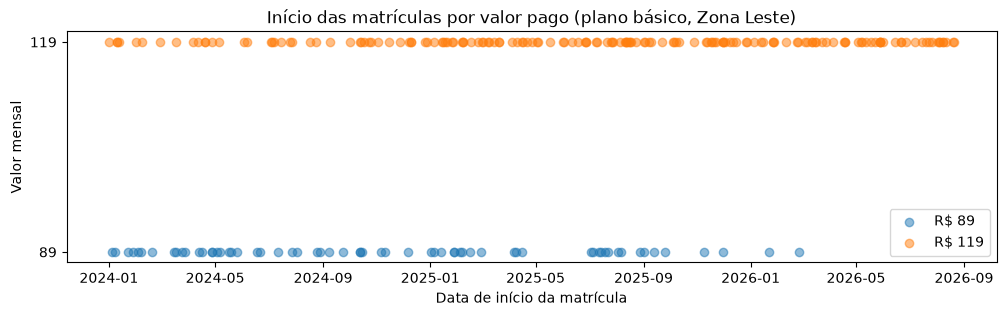

In [26]:
import matplotlib.pyplot as plt

df = pd.read_sql_query("""
SELECT id_matricula, data_inicio, valor_mensal
FROM matriculas
WHERE id_unidade = 3
  AND id_plano = 1
  AND valor_mensal IN (89, 119)
""", conexao)

df["data_inicio"] = pd.to_datetime(df["data_inicio"])

plt.figure(figsize=(12, 3))
for valor, grupo in df.groupby("valor_mensal"):
    plt.scatter(grupo["data_inicio"], [valor] * len(grupo), alpha=0.5, label=f"R$ {valor:.0f}")

plt.yticks([89, 119])
plt.title("Início das matrículas por valor pago (plano básico, Zona Leste)")
plt.xlabel("Data de início da matrícula")
plt.ylabel("Valor mensal")
plt.legend()
plt.show()

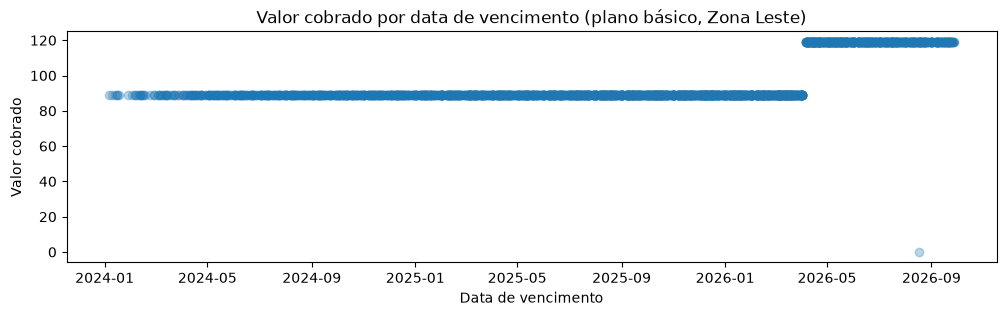

In [27]:
df = pd.read_sql_query("""
SELECT p.data_vencimento, p.valor
FROM pagamentos p
JOIN matriculas m ON m.id_matricula = p.id_matricula
WHERE m.id_unidade = 3
  AND m.id_plano = 1
""", conexao)

df["data_vencimento"] = pd.to_datetime(df["data_vencimento"])

plt.figure(figsize=(12, 3))
plt.scatter(df["data_vencimento"], df["valor"], alpha=0.3)
plt.title("Valor cobrado por data de vencimento (plano básico, Zona Leste)")
plt.xlabel("Data de vencimento")
plt.ylabel("Valor cobrado")
plt.show()

In [28]:
df[df["valor"] == 119]["data_vencimento"].min()

Timestamp('2026-04-06 00:00:00')

In [29]:
df[df["valor"] == 89]["data_vencimento"].max()

Timestamp('2026-04-02 00:00:00')

In [30]:
query = """
SELECT id_unidade,
       COUNT(*) AS total,
       SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) AS canceladas,
       ROUND(100.0 * SUM(CASE WHEN LOWER(status) = 'cancelada' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_canceladas
FROM matriculas
WHERE LOWER(status) <> 'trancada'
  AND id_plano = 1
GROUP BY id_unidade
ORDER BY id_unidade
"""

pd.read_sql_query(query, conexao)

,id_unidade,total,canceladas,pct_canceladas
0,1,382,169,44.2
1,2,273,110,40.3
2,3,226,160,70.8
3,4,273,128,46.9
4,5,172,69,40.1


In [31]:
bol = pagamentos.merge(
    matriculas[["id_matricula", "id_unidade", "id_plano", "status_limpo", "data_fim_corrigida"]],
    on="id_matricula"
)

bol = bol[
    (bol["id_unidade"] == 3) &
    (bol["id_plano"] == 1) &
    (bol["status_limpo"] != "trancada")
].copy()

bol["mes_venc"] = pd.to_datetime(bol["data_vencimento"]).dt.to_period("M")
bol["mes_fim"] = pd.to_datetime(bol["data_fim_corrigida"]).dt.to_period("M")

bol["cancelou_no_mes"] = (bol["status_limpo"] == "cancelada") & (bol["mes_fim"] == bol["mes_venc"])

resumo = bol.groupby("valor")["cancelou_no_mes"].agg(boletos="size", cancelaram="sum")
resumo["pct"] = (100 * resumo["cancelaram"] / resumo["boletos"]).round(1)

resumo

,boletos,cancelaram,pct
valor,,,
0.0,1,0,0.0
89.0,2063,46,2.2
119.0,633,65,10.3


In [32]:
todos = pagamentos.merge(
    matriculas[["id_matricula", "id_unidade", "id_plano", "status_limpo", "data_fim_corrigida"]],
    on="id_matricula"
)
todos = todos[todos["status_limpo"] != "trancada"].copy()

todos["mes_venc"] = pd.to_datetime(todos["data_vencimento"]).dt.to_period("M")
todos["mes_fim"] = pd.to_datetime(todos["data_fim_corrigida"]).dt.to_period("M")
todos["cancelou_no_mes"] = (todos["status_limpo"] == "cancelada") & (todos["mes_fim"] == todos["mes_venc"])

todos["periodo"] = (pd.to_datetime(todos["data_vencimento"]) >= "2026-04-06").map({False: "antes", True: "depois"})
todos["grupo"] = ((todos["id_unidade"] == 3) & (todos["id_plano"] == 1)).map(
    {True: "Zona Leste, básico", False: "todas as outras"}
)

resumo = todos.groupby(["grupo", "periodo"])["cancelou_no_mes"].agg(boletos="size", cancelaram="sum")
resumo["pct"] = (100 * resumo["cancelaram"] / resumo["boletos"]).round(1)

resumo

boletos  cancelaram   pct
grupo              periodo                           
Zona Leste, básico antes       2063          46   2.2
                   depois       634          65  10.3
todas as outras    antes      22060         377   1.7
                   depois      8754         174   2.0